# Predictive Maintenance: Business Intelligence and Reliability Analysis

## 1. Business Problem

Unexpected equipment failures can interrupt manufacturing operations, increase maintenance expenses and affect production efficiency.

This project analyses historical machine sensor data to understand equipment failure patterns, identify operating conditions associated with failures and support more informed maintenance planning.

## 2. Business Objectives

- Analyse machine failure frequency and distribution.
- Investigate different equipment failure categories.
- Identify relationships between sensor measurements and machine failures.
- Compare reliability patterns across machine types.
- Examine tool wear, temperature, torque and rotational speed.
- Identify operating conditions that deserve closer monitoring.
- Develop data-driven maintenance recommendations.

## 3. Dataset

AI4I 2020 Predictive Maintenance Dataset.

## 4. Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Jupyter Notebook
- Exploratory Data Analysis
- Statistical Analysis

## 5. Expected Business Outcome

Develop an evidence-based understanding of equipment reliability and identify opportunities to improve maintenance prioritisation.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("ai4i2020.csv")

# Display first five rows
display(df.head())

# Check dataset dimensions
print("Dataset Shape:", df.shape)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


Dataset Shape: (10000, 14)


In [3]:
# Dataset information
print("Dataset Information:")
df.info()

print("\nMissing Values:")
display(df.isnull().sum().to_frame(name="Missing Values"))

print("\nDuplicate Records:", df.duplicated().sum())

print("\nUnique Values in Each Column:")
display(df.nunique().to_frame(name="Unique Values"))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes:

,Missing Values
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0



Duplicate Records: 0

Unique Values in Each Column:


,Unique Values
UDI,10000
Product ID,10000
Type,3
Air temperature [K],93
Process temperature [K],82
Rotational speed [rpm],941
Torque [Nm],577
Tool wear [min],246
Machine failure,2
TWF,2


In [4]:
# Analyse machine failure distribution

failure_counts = df["Machine failure"].value_counts().sort_index()

failure_summary = pd.DataFrame({
    "Count": failure_counts,
    "Percentage": (
        failure_counts / len(df) * 100
    )
})

failure_summary.index = [
    "No Failure",
    "Machine Failure"
]

display(failure_summary.round(2))

print(
    "\nTotal Machine Failures:",
    df["Machine failure"].sum()
)

,Count,Percentage
No Failure,9661,96.61
Machine Failure,339,3.39



Total Machine Failures: 339


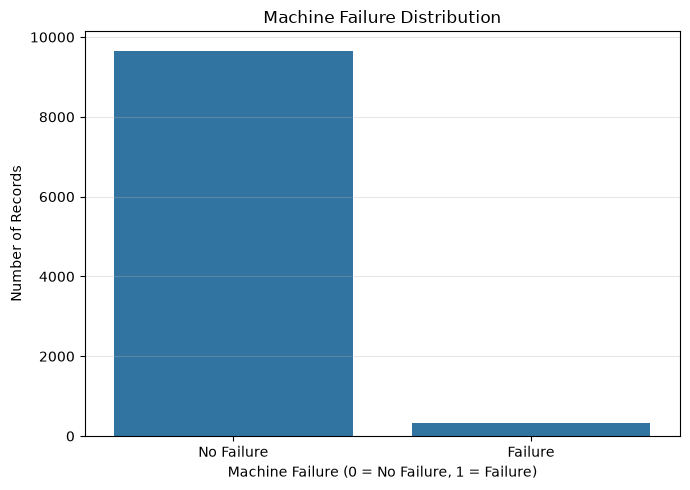

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Machine failure"
)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No Failure, 1 = Failure)")
plt.ylabel("Number of Records")

plt.xticks([0, 1], ["No Failure", "Failure"])

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# Analyse individual failure types

failure_types = ["TWF", "HDF", "PWF", "OSF", "RNF"]

failure_type_summary = pd.DataFrame({
    "Failure_Count": df[failure_types].sum()
})

failure_type_summary["Percentage_of_Records"] = (
    failure_type_summary["Failure_Count"] /
    len(df) * 100
)

failure_type_summary = failure_type_summary.sort_values(
    "Failure_Count",
    ascending=False
)

display(failure_type_summary.round(2))

,Failure_Count,Percentage_of_Records
HDF,115,1.15
OSF,98,0.98
PWF,95,0.95
TWF,46,0.46
RNF,19,0.19


Observations:
1. HDF is the most frequently recorded failure type.
2. OSF and PWF are the second and third most frequent.
3. TWF occurs less frequently, with 46 records.
4. RNF has the lowest recorded frequency, with 19 records.

Notice that the five counts add up to 373, while there are only 339 overall machine-failure records. This is possible because multiple failure indicators can be recorded for the same observation.

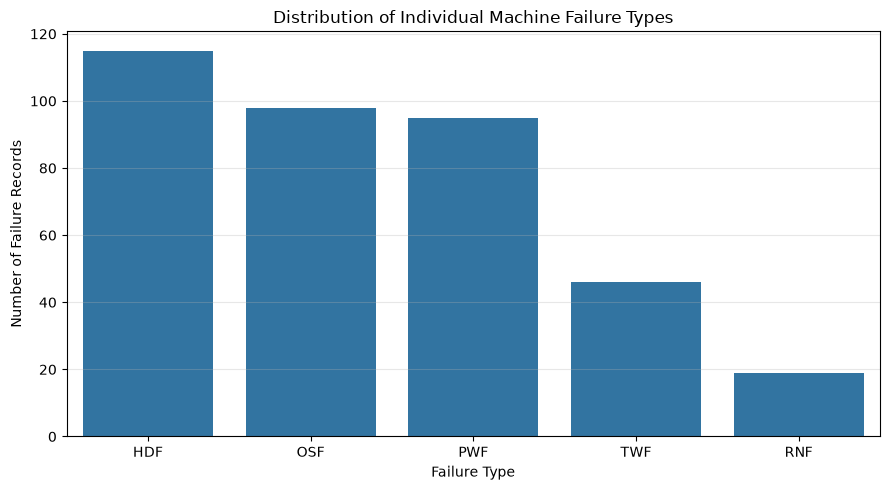

In [7]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=failure_type_summary.reset_index(),
    x="index",
    y="Failure_Count"
)

plt.title("Distribution of Individual Machine Failure Types")
plt.xlabel("Failure Type")
plt.ylabel("Number of Failure Records")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# Count failure indicators in each record

df["Failure_Type_Count"] = df[
    ["TWF", "HDF", "PWF", "OSF", "RNF"]
].sum(axis=1)

# Distribution of failure indicator counts
overlap_summary = (
    df[df["Machine failure"] == 1]
    ["Failure_Type_Count"]
    .value_counts()
    .sort_index()
)

display(
    overlap_summary.to_frame(
        name="Number_of_Machine_Records"
    )
)

print(
    "\nRecords with multiple failure indicators:",
    (df["Failure_Type_Count"] > 1).sum()
)

,Number_of_Machine_Records
Failure_Type_Count,
0,9
1,306
2,23
3,1



Records with multiple failure indicators: 24


In [9]:
# Identify records with inconsistent failure labels

failure_mismatch = df[
    (
        (df["Machine failure"] == 1) &
        (df["Failure_Type_Count"] == 0)
    ) |
    (
        (df["Machine failure"] == 0) &
        (df["Failure_Type_Count"] > 0)
    )
]

print("Total mismatched records:", len(failure_mismatch))

display(
    failure_mismatch[
        [
            "Product ID",
            "Machine failure",
            "TWF", "HDF", "PWF", "OSF", "RNF",
            "Failure_Type_Count"
        ]
    ].head(20)
)

Total mismatched records: 27


,Product ID,Machine failure,TWF,HDF,PWF,OSF,RNF,Failure_Type_Count
1221,M16081,0,0,0,0,0,1,1
1302,L48482,0,0,0,0,0,1,1
1437,H30851,1,0,0,0,0,0,0
1748,H31162,0,0,0,0,0,1,1
2072,L49252,0,0,0,0,0,1,1
2559,L49739,0,0,0,0,0,1,1
2749,M17609,1,0,0,0,0,0,0
3065,M17925,0,0,0,0,0,1,1
3452,H32866,0,0,0,0,0,1,1
4044,M18904,1,0,0,0,0,0,0


### Failure Label Consistency Analysis

A comparison between the overall Machine failure label and the five individual failure indicators identified 27 mismatched records.

Key findings:

- 18 records had Machine failure = 0 despite having an individual failure indicator.
- These records involved the RNF indicator.
- 9 records had Machine failure = 1 but no individual failure indicator.

**Business implication:** The overall machine failure label and individual failure indicators should be analysed separately. These records were retained without modification to preserve the original dataset.

*Note: A mismatch does not automatically indicate an incorrect record.*

In [10]:
# Analyse machine failure by machine type

type_failure_summary = (
    df.groupby("Type")
    .agg(
        Total_Records=("Machine failure", "count"),
        Failure_Count=("Machine failure", "sum")
    )
)

type_failure_summary["Failure_Rate_%"] = (
    type_failure_summary["Failure_Count"] /
    type_failure_summary["Total_Records"] * 100
)

display(type_failure_summary.round(2))

,Total_Records,Failure_Count,Failure_Rate_%
Type,,,
H,1003,21,2.09
L,6000,235,3.92
M,2997,83,2.77


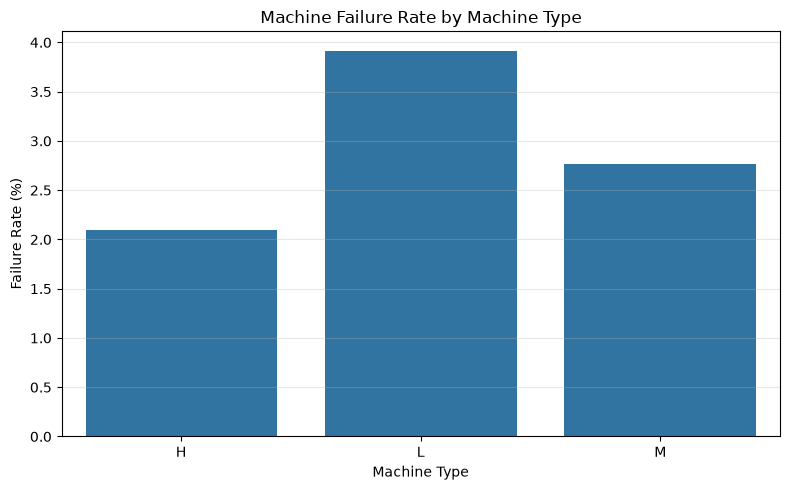

In [11]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=type_failure_summary.reset_index(),
    x="Type",
    y="Failure_Rate_%"
)

plt.title("Machine Failure Rate by Machine Type")
plt.xlabel("Machine Type")
plt.ylabel("Failure Rate (%)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
# Failure type distribution by machine type

failure_by_type = (
    df.groupby("Type")[["TWF", "HDF", "PWF", "OSF", "RNF"]]
    .sum()
)

display(failure_by_type)

,TWF,HDF,PWF,OSF,RNF
Type,,,,,
H,7,8,5,2,4
L,25,76,59,87,13
M,14,31,31,9,2


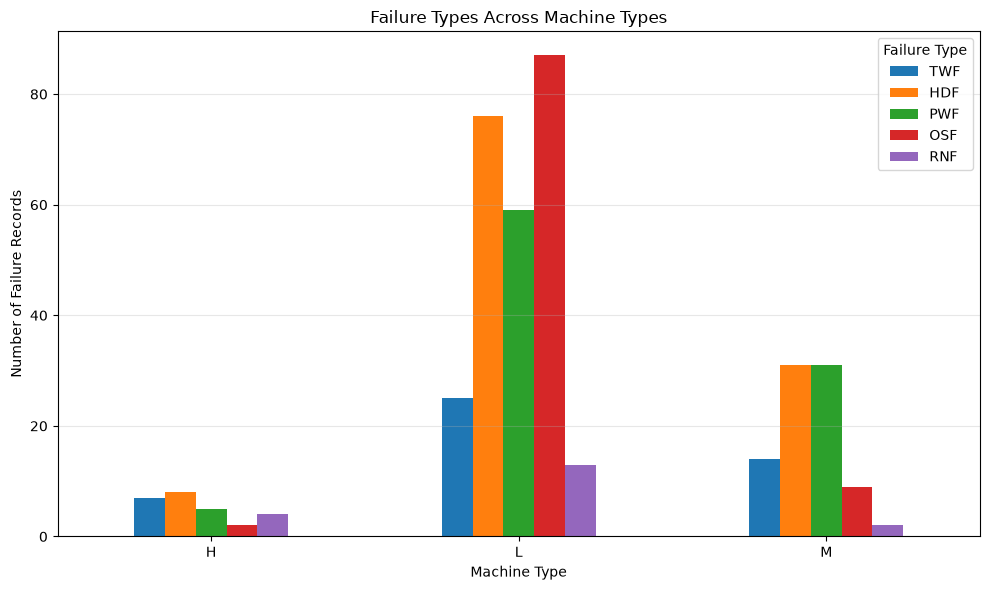

In [13]:
# Compare failure types across machine types

failure_by_type.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Failure Types Across Machine Types")
plt.xlabel("Machine Type")
plt.ylabel("Number of Failure Records")

plt.xticks(rotation=0)
plt.legend(title="Failure Type")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
# Calculate individual failure rates within each machine type

failure_rate_by_type = (
    df.groupby("Type")[["TWF", "HDF", "PWF", "OSF", "RNF"]]
    .mean() * 100
)

display(failure_rate_by_type.round(2))

,TWF,HDF,PWF,OSF,RNF
Type,,,,,
H,0.70,0.80,0.50,0.20,0.40
L,0.42,1.27,0.98,1.45,0.22
M,0.47,1.03,1.03,0.30,0.07


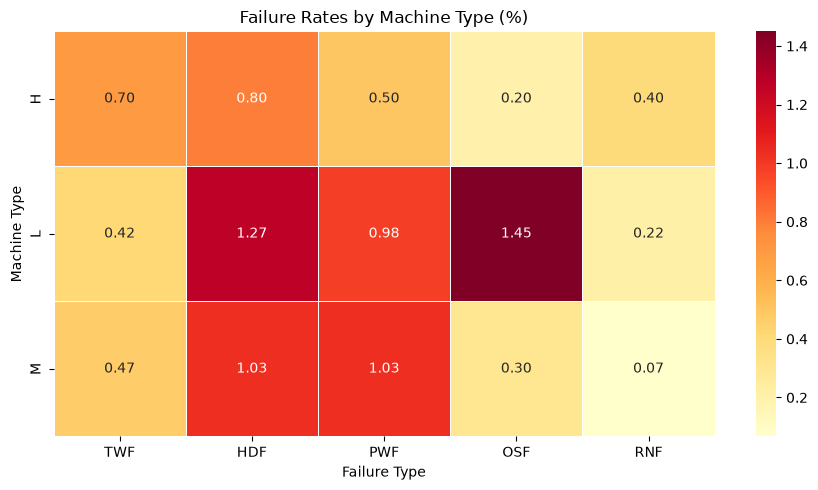

In [15]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    failure_rate_by_type,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Failure Rates by Machine Type (%)")
plt.xlabel("Failure Type")
plt.ylabel("Machine Type")

plt.tight_layout()
plt.show()

In [16]:
# Compare sensor measurements by machine failure status

sensor_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

sensor_summary = (
    df.groupby("Machine failure")[sensor_columns]
    .mean()
    .T
)

sensor_summary.columns = ["No Failure", "Machine Failure"]

display(sensor_summary.round(2))

,No Failure,Machine Failure
Air temperature [K],299.97,300.89
Process temperature [K],310.00,310.29
Rotational speed [rpm],1540.26,1496.49
Torque [Nm],39.63,50.17
Tool wear [min],106.69,143.78


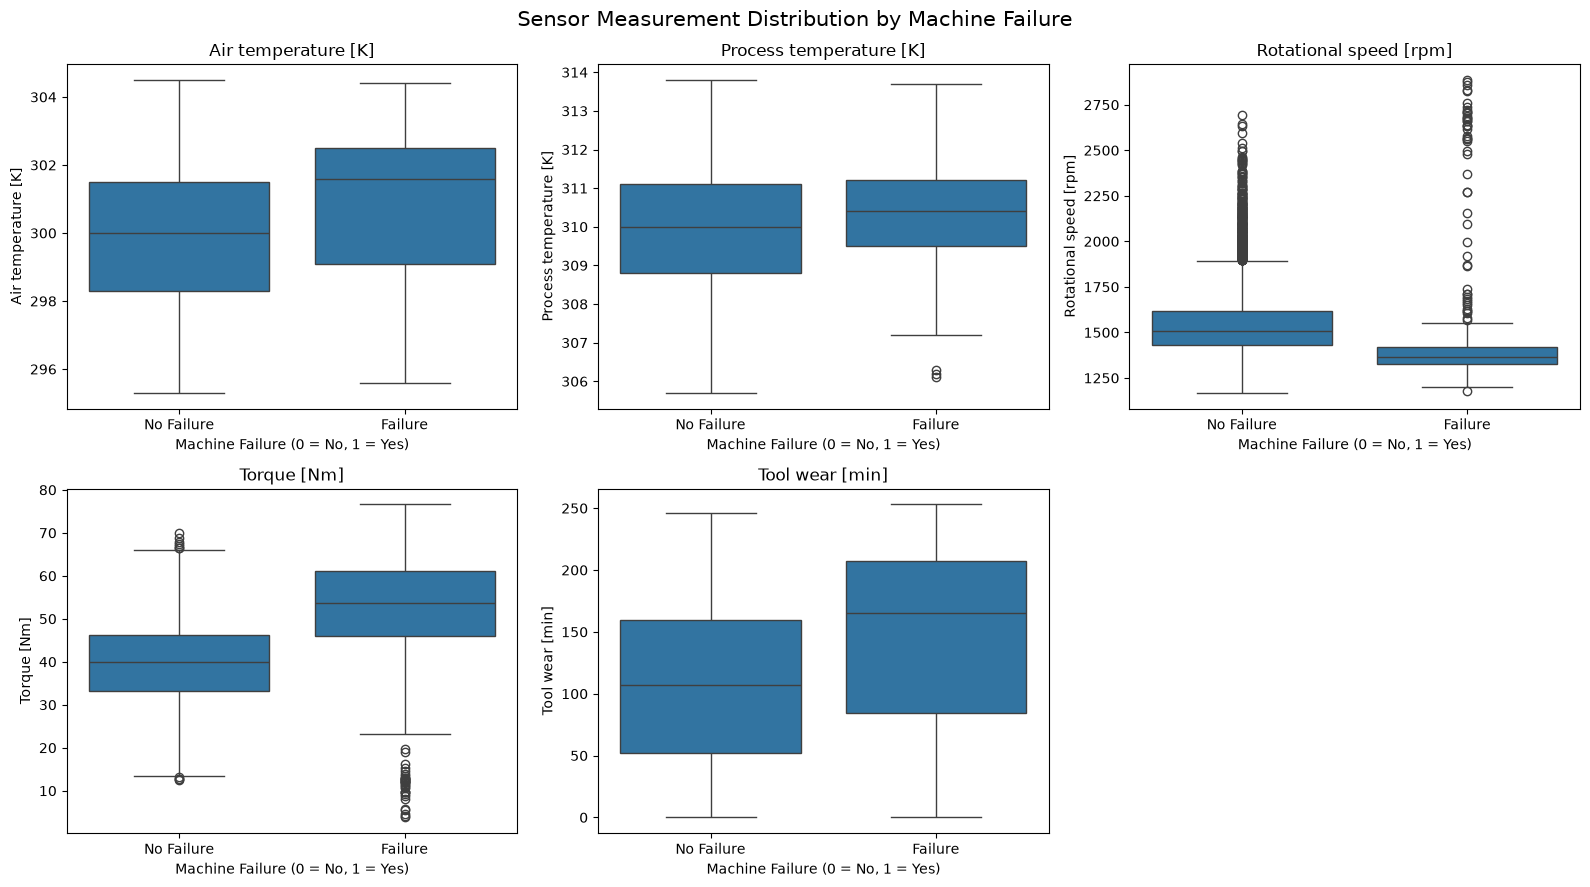

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for column, ax in zip(sensor_columns, axes.flatten()):
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=column,
        ax=ax
    )

    ax.set_title(column)
    ax.set_xlabel("Machine Failure (0 = No, 1 = Yes)")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No Failure", "Failure"])

axes.flatten()[-1].axis("off")

plt.suptitle(
    "Sensor Measurement Distribution by Machine Failure",
    fontsize=15
)

plt.tight_layout()
plt.show()

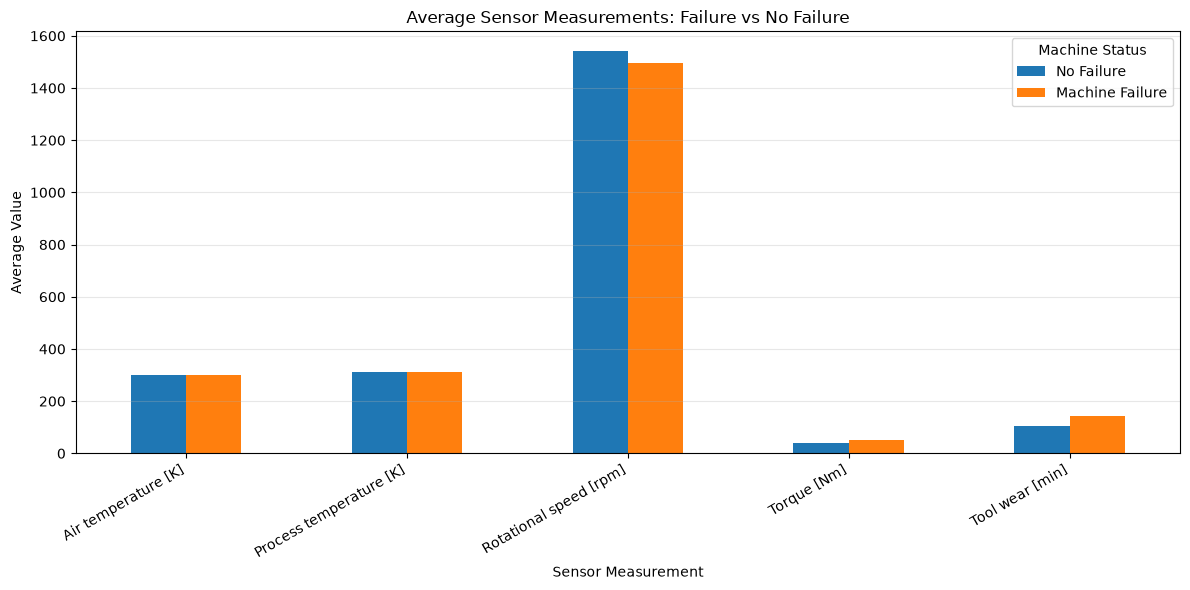

In [18]:
# Compare average sensor measurements

sensor_summary.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Sensor Measurements: Failure vs No Failure")
plt.xlabel("Sensor Measurement")
plt.ylabel("Average Value")

plt.xticks(rotation=30, ha="right")
plt.legend(title="Machine Status")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
# Group tool wear into five intervals

df["Tool_Wear_Group"] = pd.cut(
    df["Tool wear [min]"],
    bins=[-1, 50, 100, 150, 200, 300],
    labels=[
        "0–50",
        "51–100",
        "101–150",
        "151–200",
        "201+"
    ]
)

# Calculate failure rate by tool wear group

tool_wear_analysis = (
    df.groupby("Tool_Wear_Group", observed=False)
    .agg(
        Total_Records=("Machine failure", "count"),
        Failure_Count=("Machine failure", "sum"),
        Failure_Rate=("Machine failure", "mean")
    )
)

tool_wear_analysis["Failure_Rate_%"] = (
    tool_wear_analysis["Failure_Rate"] * 100
)

display(
    tool_wear_analysis.drop(columns="Failure_Rate").round(2)
)

,Total_Records,Failure_Count,Failure_Rate_%
Tool_Wear_Group,,,
0–50,2396,52,2.17
51–100,2271,53,2.33
101–150,2295,50,2.18
151–200,2276,66,2.90
201+,762,118,15.49


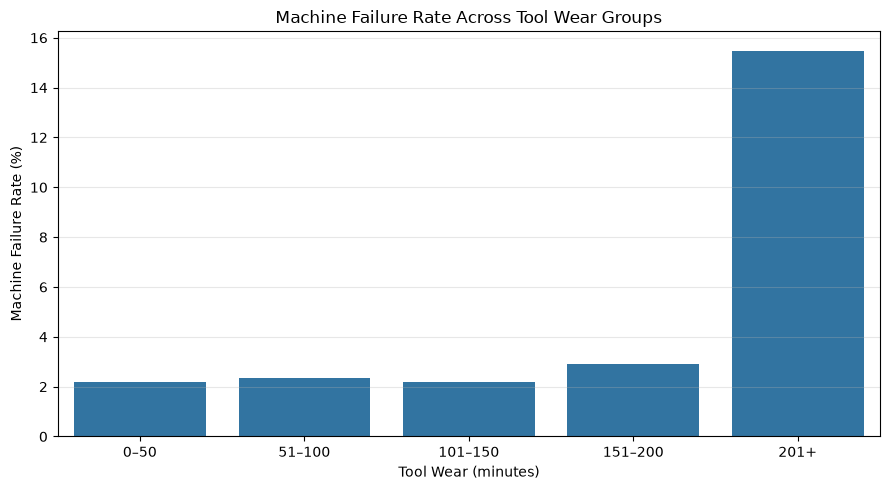

In [20]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=tool_wear_analysis.reset_index(),
    x="Tool_Wear_Group",
    y="Failure_Rate_%"
)

plt.title("Machine Failure Rate Across Tool Wear Groups")
plt.xlabel("Tool Wear (minutes)")
plt.ylabel("Machine Failure Rate (%)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
# Divide torque into five groups

df["Torque_Group"] = pd.cut(
    df["Torque [Nm]"],
    bins=[0, 20, 30, 40, 50, np.inf],
    labels=[
        "0–20",
        "21–30",
        "31–40",
        "41–50",
        "50+"
    ]
)

# Calculate failure rates by torque group

torque_analysis = (
    df.groupby("Torque_Group", observed=False)
    .agg(
        Total_Records=("Machine failure", "count"),
        Failure_Count=("Machine failure", "sum"),
        Failure_Rate=("Machine failure", "mean")
    )
)

torque_analysis["Failure_Rate_%"] = (
    torque_analysis["Failure_Rate"] * 100
)

display(
    torque_analysis.drop(columns="Failure_Rate").round(2)
)

,Total_Records,Failure_Count,Failure_Rate_%
Torque_Group,,,
0–20,233,34,14.59
21–30,1369,9,0.66
31–40,3385,19,0.56
41–50,3472,66,1.90
50+,1541,211,13.69


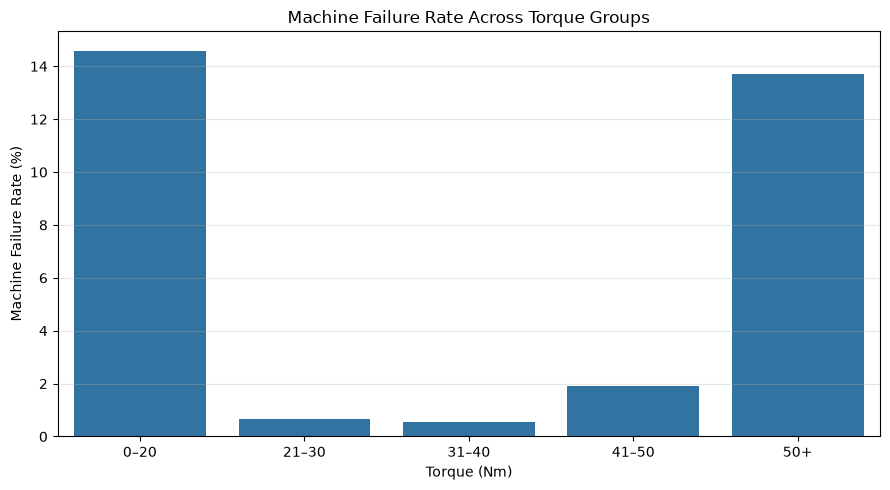

In [22]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=torque_analysis.reset_index(),
    x="Torque_Group",
    y="Failure_Rate_%"
)

plt.title("Machine Failure Rate Across Torque Groups")
plt.xlabel("Torque (Nm)")
plt.ylabel("Machine Failure Rate (%)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
# Divide rotational speed into five groups

df["Speed_Group"] = pd.cut(
    df["Rotational speed [rpm]"],
    bins=[0, 1200, 1400, 1600, 1800, np.inf],
    labels=[
        "Below 1200",
        "1200–1400",
        "1401–1600",
        "1601–1800",
        "Above 1800"
    ]
)

# Calculate failure rate by rotational speed group

speed_analysis = (
    df.groupby("Speed_Group", observed=False)
    .agg(
        Total_Records=("Machine failure", "count"),
        Failure_Count=("Machine failure", "sum"),
        Failure_Rate=("Machine failure", "mean")
    )
)

speed_analysis["Failure_Rate_%"] = (
    speed_analysis["Failure_Rate"] * 100
)

display(
    speed_analysis.drop(columns="Failure_Rate").round(2)
)

,Total_Records,Failure_Count,Failure_Rate_%
Speed_Group,,,
Below 1200,5,2,40.00
1200–1400,1865,235,12.60
1401–1600,5417,53,0.98
1601–1800,1985,12,0.60
Above 1800,728,37,5.08


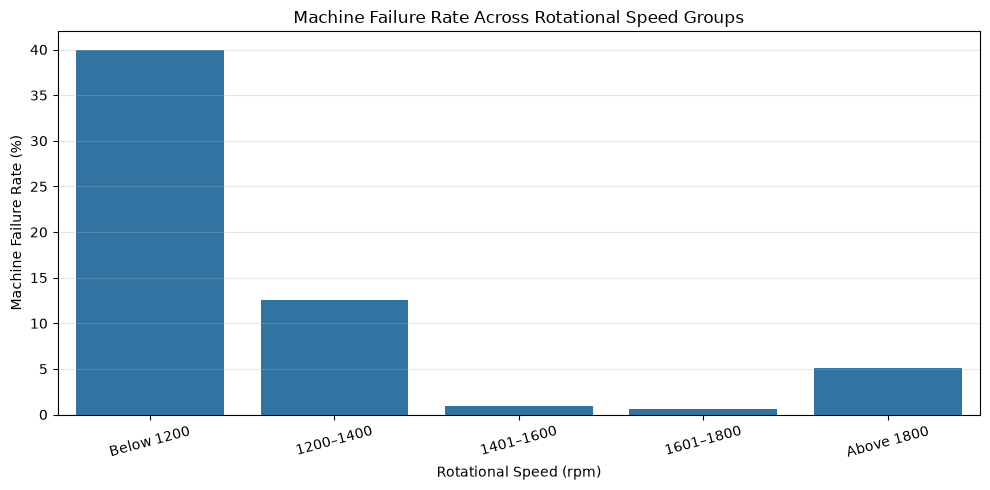

In [24]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=speed_analysis.reset_index(),
    x="Speed_Group",
    y="Failure_Rate_%"
)

plt.title("Machine Failure Rate Across Rotational Speed Groups")
plt.xlabel("Rotational Speed (rpm)")
plt.ylabel("Machine Failure Rate (%)")

plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
# Define sensor-based operating conditions

risk_conditions = {
    "Tool Wear Above 200 min":
        df["Tool wear [min]"] > 200,

    "Torque Above 50 Nm":
        df["Torque [Nm]"] > 50,

    "Rotational Speed 1200–1400 rpm":
        df["Rotational speed [rpm]"].between(1200, 1400)
}

risk_summary = []

for condition_name, condition in risk_conditions.items():

    subset = df[condition]

    risk_summary.append({
        "Operating_Condition": condition_name,
        "Total_Records": len(subset),
        "Failure_Count": subset["Machine failure"].sum(),
        "Failure_Rate_%":
            subset["Machine failure"].mean() * 100
    })

risk_summary = pd.DataFrame(risk_summary)

display(risk_summary.round(2))

,Operating_Condition,Total_Records,Failure_Count,Failure_Rate_%
0,Tool Wear Above 200 min,762,118,15.49
1,Torque Above 50 Nm,1541,211,13.69
2,Rotational Speed 1200–1400 rpm,1866,236,12.65


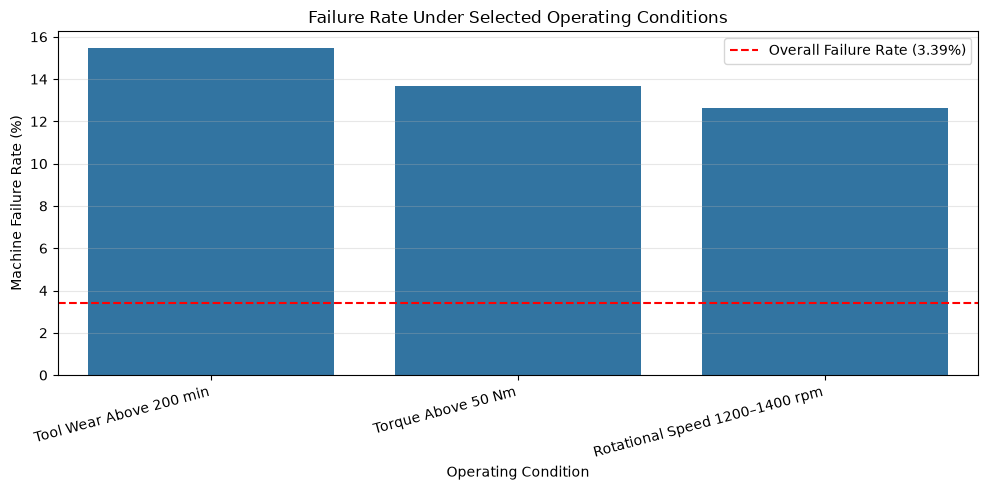

In [26]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=risk_summary,
    x="Operating_Condition",
    y="Failure_Rate_%"
)

plt.axhline(
    y=df["Machine failure"].mean() * 100,
    color="red",
    linestyle="--",
    label="Overall Failure Rate (3.39%)"
)

plt.title("Failure Rate Under Selected Operating Conditions")
plt.xlabel("Operating Condition")
plt.ylabel("Machine Failure Rate (%)")

plt.xticks(rotation=15, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [27]:
# Create binary indicators for operating conditions

df["High_Tool_Wear"] = (
    df["Tool wear [min]"] > 200
)

df["High_Torque"] = (
    df["Torque [Nm]"] > 50
)

df["Low_Mid_Speed"] = (
    df["Rotational speed [rpm]"].between(1200, 1400)
)

# Count how many conditions each record satisfies

df["Risk_Condition_Count"] = df[
    ["High_Tool_Wear", "High_Torque", "Low_Mid_Speed"]
].sum(axis=1)

# Summarise failure rates by number of conditions

combined_risk_analysis = (
    df.groupby("Risk_Condition_Count")
    .agg(
        Total_Records=("Machine failure", "count"),
        Failure_Count=("Machine failure", "sum"),
        Failure_Rate=("Machine failure", "mean")
    )
)

combined_risk_analysis["Failure_Rate_%"] = (
    combined_risk_analysis["Failure_Rate"] * 100
)

display(
    combined_risk_analysis.drop(
        columns="Failure_Rate"
    ).round(2)
)

,Total_Records,Failure_Count,Failure_Rate_%
Risk_Condition_Count,,,
0,7140,37,0.52
1,1635,90,5.50
2,1141,161,14.11
3,84,51,60.71


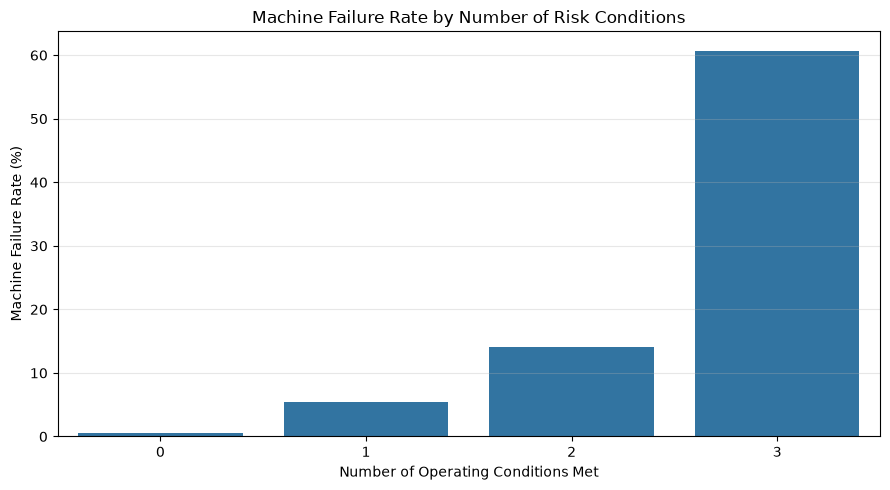

In [28]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=combined_risk_analysis.reset_index(),
    x="Risk_Condition_Count",
    y="Failure_Rate_%"
)

plt.title("Machine Failure Rate by Number of Risk Conditions")
plt.xlabel("Number of Operating Conditions Met")
plt.ylabel("Machine Failure Rate (%)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
# Analyse each combination of the three operating conditions

combination_analysis = (
    df.groupby(
        ["High_Tool_Wear", "High_Torque", "Low_Mid_Speed"],
        observed=False
    )
    .agg(
        Total_Records=("Machine failure", "count"),
        Failure_Count=("Machine failure", "sum"),
        Failure_Rate=("Machine failure", "mean")
    )
)

combination_analysis["Failure_Rate_%"] = (
    combination_analysis["Failure_Rate"] * 100
)

combination_analysis = combination_analysis.sort_values(
    "Failure_Rate_%",
    ascending=False
)

display(
    combination_analysis.drop(
        columns="Failure_Rate"
    ).round(2)
)

Total_Records  Failure_Count  \
High_Tool_Wear High_Torque Low_Mid_Speed                                 
True           True        True                      84             51   
                           False                     23             11   
               False       True                      67             14   
False          True        True                    1051            136   
True           False       False                    588             42   
False          False       True                     664             35   
               True        False                    383             13   
               False       False                   7140             37   

                                          Failure_Rate_%  
High_Tool_Wear High_Torque Low_Mid_Speed                  
True           True        True                    60.71  
                           False                   47.83  
               False       True                    20.90  
False          True        True                    12.94  
True           False       False                    7.14  
False          False       True                     5.27  
               True        False                    3.39  
               False       False                    0.52

In [30]:
# Convert the multi-index into ordinary columns

combination_readable = (
    combination_analysis
    .reset_index()
    .sort_values("Failure_Rate_%", ascending=False)
)

display(
    combination_readable.round(2)
)

,High_Tool_Wear,High_Torque,Low_Mid_Speed,Total_Records,Failure_Count,Failure_Rate,Failure_Rate_%
0,True,True,True,84,51,0.61,60.71
1,True,True,False,23,11,0.48,47.83
2,True,False,True,67,14,0.21,20.90
3,False,True,True,1051,136,0.13,12.94
4,True,False,False,588,42,0.07,7.14
5,False,False,True,664,35,0.05,5.27
6,False,True,False,383,13,0.03,3.39
7,False,False,False,7140,37,0.01,0.52


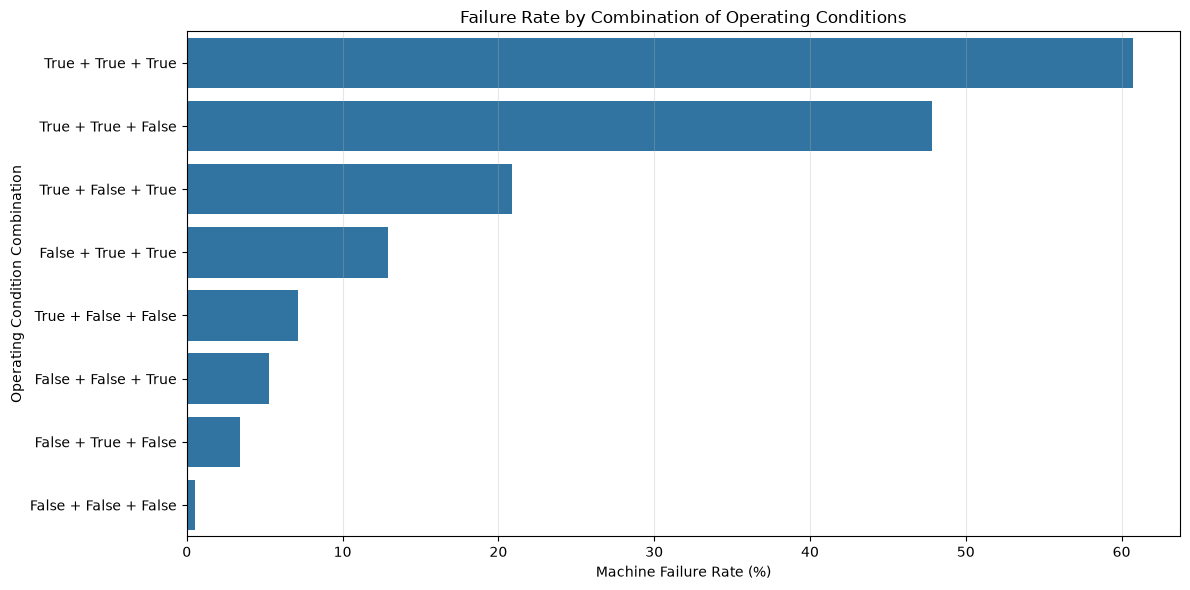

In [31]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=combination_readable,
    x="Failure_Rate_%",
    y=combination_readable[
        ["High_Tool_Wear", "High_Torque", "Low_Mid_Speed"]
    ].astype(str).agg(" + ".join, axis=1)
)

plt.title("Failure Rate by Combination of Operating Conditions")
plt.xlabel("Machine Failure Rate (%)")
plt.ylabel("Operating Condition Combination")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
# Create maintenance prioritisation table

maintenance_priority = combination_readable.copy()

maintenance_priority["Priority"] = np.select(
    [
        (maintenance_priority["Failure_Rate_%"] >= 20) &
        (maintenance_priority["Total_Records"] >= 50),

        (maintenance_priority["Failure_Rate_%"] >= 10),

        (maintenance_priority["Failure_Rate_%"] >= 3)
    ],
    [
        "High Priority",
        "Investigate",
        "Monitor"
    ],
    default="Lower Observed Priority"
)

maintenance_priority = maintenance_priority[
    [
        "High_Tool_Wear",
        "High_Torque",
        "Low_Mid_Speed",
        "Total_Records",
        "Failure_Count",
        "Failure_Rate_%",
        "Priority"
    ]
]

display(maintenance_priority.round(2))

,High_Tool_Wear,High_Torque,Low_Mid_Speed,Total_Records,Failure_Count,Failure_Rate_%,Priority
0,True,True,True,84,51,60.71,High Priority
1,True,True,False,23,11,47.83,Investigate
2,True,False,True,67,14,20.90,High Priority
3,False,True,True,1051,136,12.94,Investigate
4,True,False,False,588,42,7.14,Monitor
5,False,False,True,664,35,5.27,Monitor
6,False,True,False,383,13,3.39,Monitor
7,False,False,False,7140,37,0.52,Lower Observed Priority


## Maintenance Prioritisation: Key Business Findings

The analysis examined three operating conditions:

- High tool wear: above 200 minutes
- High torque: above 50 Nm
- Rotational speed: between 1,200 and 1,400 rpm

### Key Findings

1. Records meeting all three conditions had a 60.71% observed failure rate (51 failures across 84 records).
2. Records with high tool wear and high torque had a 47.83% failure rate (11 failures across 23 records).
3. Records with high tool wear and low-mid rotational speed had a 20.90% failure rate.
4. Records with high torque and low-mid speed had a 12.94% failure rate across 1,051 records.
5. Records meeting none of the selected conditions had a 0.52% failure rate.

### Business Recommendations

- Prioritise further investigation of machines exhibiting multiple unusual operating conditions.
- Closely monitor machines with high accumulated tool wear.
- Investigate abnormal torque and rotational speed combinations.
- Use sensor measurements to support maintenance inspections.
- Validate potential maintenance thresholds using additional operational data before implementing them.

### Important Limitations

- The analysis is based on historical labelled records.
- The operating conditions are exploratory thresholds, not validated engineering limits.
- Some combinations have relatively small sample sizes.
- The operating conditions overlap.
- Observed associations do not establish causation.
- These findings should not be interpreted as proof that a maintenance intervention will prevent failures.

In [33]:
# Calculate average sensor measurements for each failure type

failure_sensor_analysis = {}

for failure_type in ["TWF", "HDF", "PWF", "OSF", "RNF"]:

    failure_sensor_analysis[failure_type] = (
        df.groupby(failure_type)[sensor_columns]
        .mean()
        .loc[1]
    )

failure_sensor_summary = pd.DataFrame(
    failure_sensor_analysis
).T

display(failure_sensor_summary.round(2))

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
TWF,300.30,310.17,1566.17,37.84,216.37
HDF,302.56,310.79,1337.26,53.17,107.19
PWF,300.08,309.95,1763.97,48.51,101.88
OSF,300.04,310.07,1350.33,58.37,207.69
RNF,300.82,310.76,1485.00,43.67,124.47


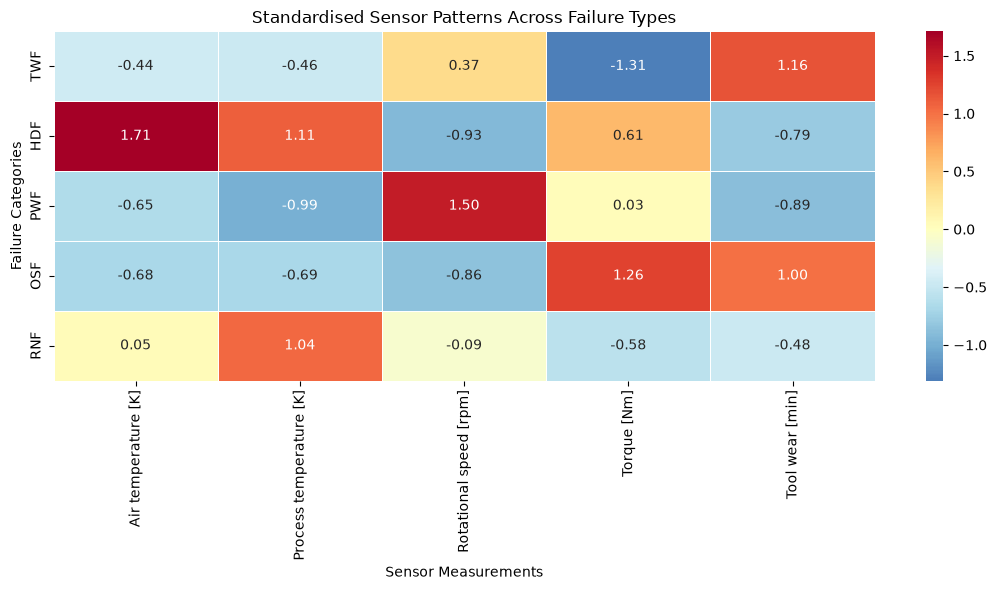

In [34]:
# Standardise sensor averages across failure types

failure_sensor_scaled = (
    failure_sensor_summary -
    failure_sensor_summary.mean()
) / failure_sensor_summary.std()

plt.figure(figsize=(11, 6))

sns.heatmap(
    failure_sensor_scaled,
    annot=True,
    fmt=".2f",
    cmap="RdYlBu_r",
    center=0,
    linewidths=0.5
)

plt.title("Standardised Sensor Patterns Across Failure Types")
plt.xlabel("Sensor Measurements")
plt.ylabel("Failure Categories")

plt.tight_layout()
plt.show()

In [35]:
# Calculate individual failure rates by machine type

failure_type_rates = (
    df.groupby("Type")[["TWF", "HDF", "PWF", "OSF", "RNF"]]
    .mean() * 100
)

display(failure_type_rates.round(2))

,TWF,HDF,PWF,OSF,RNF
Type,,,,,
H,0.70,0.80,0.50,0.20,0.40
L,0.42,1.27,0.98,1.45,0.22
M,0.47,1.03,1.03,0.30,0.07


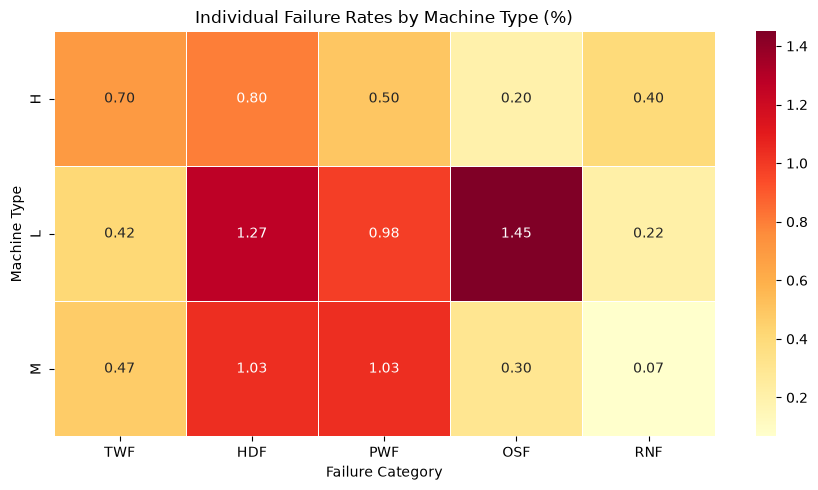

In [36]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    failure_type_rates,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Individual Failure Rates by Machine Type (%)")
plt.xlabel("Failure Category")
plt.ylabel("Machine Type")

plt.tight_layout()
plt.show()

# Executive Summary

## Project Overview

This analysis investigates machine reliability and maintenance patterns using 10,000 manufacturing records. The objective is to identify sensor patterns, operating conditions and machine characteristics associated with machine failures.

## Key Findings

### 1. Overall Machine Reliability

- Total records analysed: 10,000.
- Machine failure records: 339.
- Overall observed failure rate: 3.39%.
- The dataset contains a significant imbalance between normal and failure-labelled records.

### 2. Failure Category Analysis

- Heat Dissipation Failure (HDF): 115 records.
- Overstrain Failure (OSF): 98 records.
- Power Failure (PWF): 95 records.
- Tool Wear Failure (TWF): 46 records.
- Random Failure (RNF): 19 records.

HDF was the most frequently recorded individual failure category.

### 3. Machine Type Analysis

- Type L had the highest overall failure rate at 3.92%.
- Type M had a failure rate of 2.77%.
- Type H had a failure rate of 2.09%.

Type L showed particularly high OSF and HDF rates.

### 4. Sensor Measurement Findings

Failure-labelled records showed:

- Higher average torque.
- Higher average tool wear.
- Lower average rotational speed.
- Slightly higher air and process temperatures.

Different failure categories also showed distinct average sensor profiles.

### 5. Operating Condition Analysis

Three conditions were selected for exploratory investigation:

- Tool wear above 200 minutes.
- Torque above 50 Nm.
- Rotational speed between 1,200 and 1,400 rpm.

Their individual observed failure rates were:

- High tool wear: 15.49%.
- High torque: 13.69%.
- Selected rotational speed range: 12.65%.

### 6. Combined Operating Conditions

The highest observed failure rate occurred when all three selected conditions were present:

- Records: 84.
- Failure records: 51.
- Observed failure rate: 60.71%.

Records meeting none of these conditions had an observed failure rate of 0.52%.

## Overall Business Insight

The analysis identifies tool wear, torque, rotational speed and machine type as useful areas for further equipment reliability investigation.

Combining multiple sensor conditions may help maintenance teams identify groups of records with higher observed failure frequencies.

These findings can support further investigation and the development of predictive maintenance strategies.

## Business Recommendations

Based on the exploratory findings, the following actions are recommended for further investigation:

### 1. Monitor Tool Wear

- Pay closer attention to machines with tool wear exceeding 200 minutes.
- Investigate whether increased tool wear is associated with maintenance requirements.
- Evaluate appropriate inspection intervals using actual equipment operating data.

### 2. Investigate Abnormal Torque Conditions

- Examine machines operating above 50 Nm torque.
- Investigate unusually low torque conditions as well.
- Review whether these measurements are consistent with expected operating specifications.

### 3. Monitor Rotational Speed

- Investigate the elevated failure frequency observed in the 1,200–1,400 rpm range.
- Examine machines operating outside their expected speed ranges.
- Validate operating thresholds with engineering teams before implementation.

### 4. Develop Machine-Specific Maintenance Strategies

- Investigate the higher observed failure rates for Type L machines.
- Examine the different failure profiles across machine types.
- Consider machine-specific inspection and maintenance procedures.

### 5. Explore Predictive Maintenance

- Use historical sensor measurements to develop and validate machine failure prediction models.
- Evaluate models using precision, recall, F1-score and PR-AUC.
- Prioritise detecting failures while controlling unnecessary maintenance alerts.

## Limitations of the Analysis

1. **Class imbalance:** Only 3.39% of records are labelled as machine failures.

2. **Limited observations:** The dataset contains 10,000 records and may not represent all real-world manufacturing environments.

3. **Failure label inconsistencies:** Some records have mismatches between the overall machine failure label and individual failure indicators. These should be investigated before model development.

4. **Overlapping failure categories:** Individual failure indicators are not mutually exclusive, and one record may contain multiple failure labels.

5. **No time-series information:** The dataset does not provide a machine-level chronological history suitable for analysing degradation over time.

6. **Exploratory thresholds:** The selected tool wear, torque and rotational speed thresholds are analytical choices, not validated engineering limits.

7. **Association versus causation:** The observed relationships do not establish that a particular sensor condition causes machine failure.

8. **No financial information:** The dataset does not contain maintenance costs, downtime costs or production losses. Therefore, financial savings cannot be estimated.

## Conclusion

This exploratory analysis identified several sensor measurements and operating conditions associated with machine failure records.

Tool wear, torque, rotational speed and machine type showed useful patterns for further reliability investigation.

The combined-condition analysis highlighted a group with a 60.71% observed failure rate, although this group contained only 84 records.

These findings provide a foundation for further predictive modelling and maintenance investigation. They should be validated using additional operational data before being converted into real-world maintenance policies.